# Exploratory Data Analysis - Starter

A guided template for my first EDA project. Replace the sample code and notes with your own.

**Dataset:** _add the dataset name and source link here_  
**Goal:** _one sentence on the question you are answering_

## 1. Imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
pd.set_option('display.max_columns', None)

## 2. Load the data

In [ ]:
# df = pd.read_csv('../data/your_dataset.csv')
# df.head()

In [4]:
import pandas as pd
df = pd.read_csv('/content/train.csv') #  train.csv file is uploaded
df.head() # first 5 rows displayed

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Inspect

In [ ]:
# df.shape -- (no.of.rows, no.of.columns)
# df.info() -- the total no.of rows, all column names, non-null count, datatype
# df.describe(include='all') -- simple describe command will show only numeric values & include='all' -- will include both texts & numeric values
# df.isnull().sum() - total no.of null values in each column

In [4]:
df.shape

(891, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe(include='all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [7]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


## 4. Clean

In [ ]:
# handle missing values, fix dtypes, drop duplicates

In [ ]:
# df['Age'] = df['Age'].fillna(df['Age'].median()) -- the missing values in Age is filled out with median value of the age
# df = df.drop(columns=['Cabin']) -- since cabin has many missing values, the whole column is dropped
# df = df.dropna(subset=['Embarked']) -- embark only has 2 rows with missing values, so subset=['embark'] checks the Nan values in embark column & removes those rows
# df = df.drop_duplicates() -- duplicate values in the table (after above three edits) will be dropped
# df.isnull().sum() -- shows the total null values in each columns

In [12]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [17]:
df = df.drop(columns=['Cabin']) # column dropped

In [16]:
original = pd.read_csv("train.csv")
df['Cabin'] = original['Cabin']

# To take just the dropped column from a fresh copy

/tmp/ipykernel_1061/2854345082.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Cabin'] = original['Cabin']


In [18]:
df = df.dropna(subset=['Embarked'])

In [19]:
df = df.drop_duplicates()

In [20]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## 5. Explore

In [ ]:
# value counts, group-bys, correlations

In [28]:
# finding the overall survival rates ------------------------------------

# df['Survived'].mean() -- the mean value of survived column
# df.groupby('Sex')['Survived'].mean() -- the mean value of survived column is grouped by Sex ( male, female )
# df.groupby('Pclass')['Survived'].mean() -- the mean value of survived column is grouped by pclass ( 1,2,3 )
# df.groupby(['Sex', 'Pclass'])['Survived'].mean() -- the mean value of survived column is grouped by sex & pclass ( male-1,2,3 & female-1,2,3)

# in last line the [ ] inside ( ) is a Python list: ['Sex', 'Pclass'] is a list of column names.
# Square brackets also make lists, so:
# groupby('Sex'): one column, just pass its name.
# groupby(['Sex', 'Pclass']): more than one column, so pass them as a list.

# Round brackets ( ) are for calling a function or method, meaning “do this action.”
# groupby(...) and mean() are methods, so they get ( ). ---- Whatever you pass inside is the input to that action.
# Square brackets [ ] are for selecting a column from the DataFrame, meaning “pick this one.”

In [27]:
df['Survived'].mean() # as per answer roughly 38% of passengers survived

np.float64(0.38245219347581555)

In [22]:
df.groupby('Sex')['Survived'].mean()

,Survived
Sex,
female,0.740385
male,0.188908


In [23]:
df.groupby('Pclass')['Survived'].mean()

,Survived
Pclass,
1,0.626168
2,0.472826
3,0.242363


In [24]:
df.groupby(['Sex', 'Pclass'])['Survived'].mean()

Sex     Pclass
female  1         0.967391
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

## 6. Visualise

In [ ]:
# bar charts, histograms, heatmap

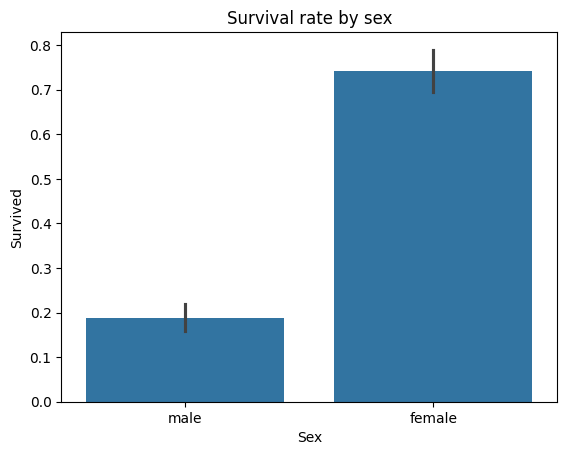

In [6]:
sns.barplot(data=df, x='Sex', y='Survived')
plt.title('Survival rate by sex')
plt.show()

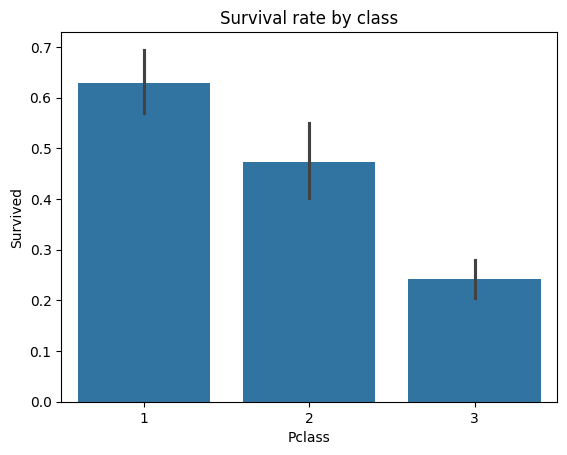

In [7]:
sns.barplot(data=df, x='Pclass', y='Survived')
plt.title('Survival rate by class')
plt.show()

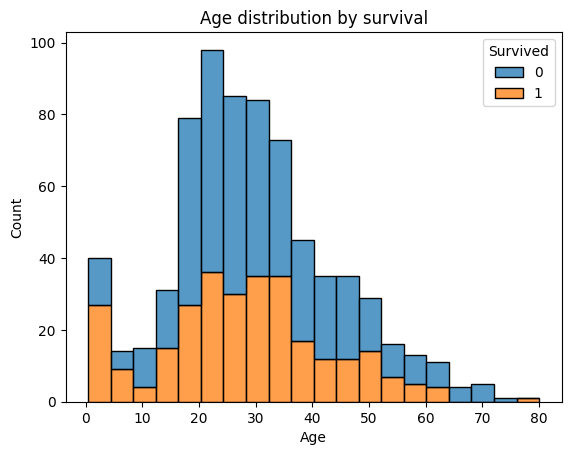

In [8]:
sns.histplot(data=df, x='Age', hue='Survived', multiple='stack')
plt.title('Age distribution by survival')
plt.show()

## 7. Key insights

1.
2.
3.

In [ ]:
# 1. Women survided more copared to men
# 2. First class & Second class Women survived more than Third class women
# 3. Children around 5 & Adults around 20 to 35 aged survided more than other aged people
# 4. In whole, roughly 38% of passengers survived
# 5. About 96% of 1st class women survived. Whereas only 36% of 1st class men survived
# 6. Least survived group was 3rd class men